# HW2 : Uniform Convergence and the Limits of Learning

## Part I – Simulating Uniform Convergence

### Task 1 : Empirical Risk as a Random Variable

On considère une classe finie $\mathcal{H} = \{h_1, \dots, h_K\}$ où chaque hypothèse $h_j$ a une vraie erreur $L_D(h_j) = p_j$.

Sur un échantillon de taille $m$, le nombre d'erreurs est $E_j \sim \text{Binomial}(m, p_j)$ et le risque empirique est $L_S(h_j) = E_j / m$.

**Rappel théorique :**
- $\mathbb{E}[L_S(h_j)] = \dfrac{\mathbb{E}[E_j]}{m} = \dfrac{m p_j}{m} = p_j$ → le risque empirique est un estimateur **sans biais** du vrai risque.
- $\text{Var}(L_S(h_j)) = \dfrac{\text{Var}(E_j)}{m^2} = \dfrac{m p_j (1-p_j)}{m^2} = \dfrac{p_j(1-p_j)}{m}$, donc l'écart-type vaut $\sqrt{p_j(1-p_j)/m}$ et diminue en $1/\sqrt{m}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Graine fixée pour que les résultats soient reproductibles
rng = np.random.default_rng(0)

### Choix des paramètres

- **Vrais risques** $p_1, \dots, p_K$ : on prend $K = 5$ hypothèses avec des risques variés, de très bonne ($0.05$) à aléatoire ($0.5$).
- **Hypothèse étudiée** : $h_3$ avec $p_3 = 0.3$ (valeur intermédiaire, ni trop proche de 0 ni de 0.5).
- **Tailles d'échantillon** $m$ : de 10 à 1000, pour couvrir les petits et grands échantillons.
- **Nombre de répétitions** : 10 000, ce qui suffit pour avoir des histogrammes et des moyennes précises.

In [2]:
# Vrais risques des K hypothèses
p = np.array([0.05, 0.1, 0.3, 0.4, 0.5])

# Hypothèse étudiée : h_3 (indice 2 en Python)
j = 2
p_j = p[j]

# Tailles d'échantillon testées
m_values = [10, 50, 100, 500, 1000]

# Nombre de répétitions Monte-Carlo
n_rep = 10000

print("Hypothèse étudiée : h_%d, vrai risque p = %.2f" % (j + 1, p_j))

Hypothèse étudiée : h_3, vrai risque p = 0.30


### (a) et (b) : Simulation de $E_j$ et calcul de $L_S(h_j)$

Pour chaque $m$, on tire $E_j \sim \text{Binomial}(m, p_j)$ un grand nombre de fois, puis on divise par $m$.

In [3]:
# Dictionnaire : pour chaque m, le tableau des n_rep risques empiriques simulés
L_S = {}

for m in m_values:
    E_j = rng.binomial(m, p_j, size=n_rep)   # (a) nombre d'erreurs sur chaque échantillon
    L_S[m] = E_j / m                         # (b) risque empirique

### (c) : Visualisation de la distribution de $L_S(h_j)$

Un histogramme par valeur de $m$. La ligne rouge indique le vrai risque $p_j$. On garde le même axe horizontal pour pouvoir comparer la largeur des distributions.

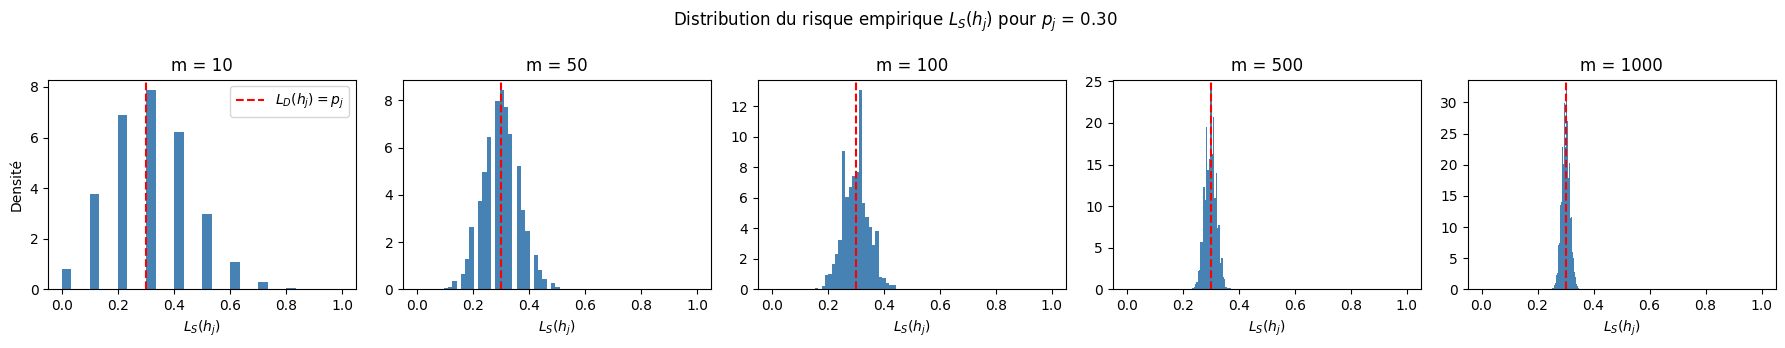

In [4]:
fig, axes = plt.subplots(1, len(m_values), figsize=(18, 3.5), sharex=True)

for ax, m in zip(axes, m_values):
    ax.hist(L_S[m], bins=30, density=True, color="steelblue")
    ax.axvline(p_j, color="red", linestyle="--", label="$L_D(h_j) = p_j$")
    ax.set_title("m = %d" % m)
    ax.set_xlabel("$L_S(h_j)$")

axes[0].set_ylabel("Densité")
axes[0].legend()
fig.suptitle("Distribution du risque empirique $L_S(h_j)$ pour $p_j$ = %.2f" % p_j)
plt.tight_layout()
plt.show()

**Observation :** pour $m = 10$, $L_S(h_j)$ ne peut prendre que les valeurs $0, 0.1, 0.2, \dots$ et la distribution est très étalée (on peut obtenir 0 comme 0.7). Quand $m$ augmente, l'histogramme se resserre autour de $p_j = 0.3$ et prend une forme de cloche (approximation normale de la binomiale).

### (d) : Comparaison de la moyenne empirique avec le vrai risque

On compare aussi l'écart-type observé avec l'écart-type théorique $\sqrt{p_j(1-p_j)/m}$.

In [5]:
print("   m  | moyenne L_S | vrai p_j | écart-type observé | écart-type théorique")
print("-" * 75)

std_obs = []
std_th = []

for m in m_values:
    moyenne = L_S[m].mean()
    s_obs = L_S[m].std()
    s_th = np.sqrt(p_j * (1 - p_j) / m)
    std_obs.append(s_obs)
    std_th.append(s_th)
    print("%5d |   %.4f    |  %.2f    |      %.4f        |      %.4f" % (m, moyenne, p_j, s_obs, s_th))

   m  | moyenne L_S | vrai p_j | écart-type observé | écart-type théorique
---------------------------------------------------------------------------
   10 |   0.3001    |  0.30    |      0.1452        |      0.1449
   50 |   0.3010    |  0.30    |      0.0644        |      0.0648
  100 |   0.2996    |  0.30    |      0.0456        |      0.0458
  500 |   0.2997    |  0.30    |      0.0202        |      0.0205
 1000 |   0.3001    |  0.30    |      0.0145        |      0.0145


**Observation :** quel que soit $m$, la moyenne des $L_S(h_j)$ simulés est très proche de $p_j = 0.3$ : le risque empirique est bien **sans biais**. Les petites différences viennent uniquement du nombre fini de répétitions Monte-Carlo.

L'écart-type observé correspond très bien à la formule théorique $\sqrt{p_j(1-p_j)/m}$.

### Évolution de la variabilité avec $m$

On trace l'écart-type de $L_S(h_j)$ en fonction de $m$ (échelle log-log), observé et théorique.

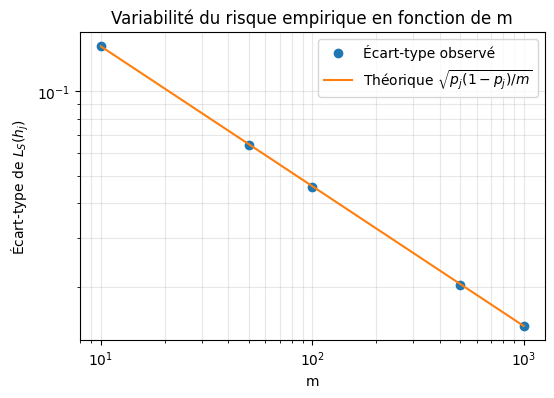

In [6]:
plt.figure(figsize=(6, 4))
plt.plot(m_values, std_obs, "o", label="Écart-type observé")
plt.plot(m_values, std_th, "-", label=r"Théorique $\sqrt{p_j(1-p_j)/m}$")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("m")
plt.ylabel("Écart-type de $L_S(h_j)$")
plt.title("Variabilité du risque empirique en fonction de m")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Même expérience pour toutes les hypothèses

Pour vérifier que la conclusion ne dépend pas du choix de $h_j$, on répète le calcul de la moyenne et de l'écart-type pour les $K$ hypothèses.

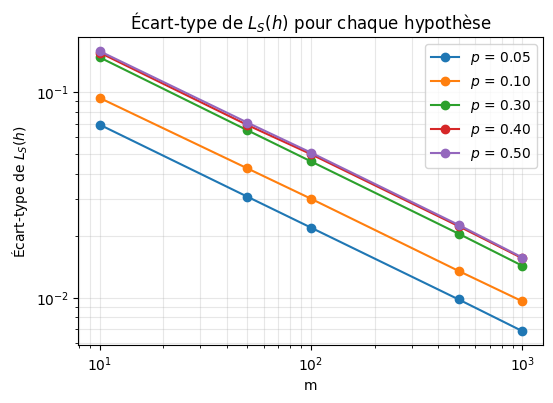

In [7]:
plt.figure(figsize=(6, 4))

for k in range(len(p)):
    stds = []
    for m in m_values:
        L = rng.binomial(m, p[k], size=n_rep) / m
        stds.append(L.std())
    plt.plot(m_values, stds, "o-", label="$p$ = %.2f" % p[k])

plt.xscale("log")
plt.yscale("log")
plt.xlabel("m")
plt.ylabel("Écart-type de $L_S(h)$")
plt.title("Écart-type de $L_S(h)$ pour chaque hypothèse")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Discussion : comment la variabilité de $L_S(h_j)$ change quand $m$ augmente

- **La moyenne ne change pas** : pour tout $m$, $\mathbb{E}[L_S(h_j)] = p_j$. Augmenter $m$ ne corrige pas un biais (il n'y en a pas), cela réduit seulement le bruit.
- **La dispersion diminue** : l'écart-type suit $\sqrt{p_j(1-p_j)/m}$, c'est-à-dire qu'il décroît en $1/\sqrt{m}$. Sur le graphique log-log, c'est une droite de pente $-1/2$ : multiplier $m$ par 100 (de 10 à 1000) divise l'écart-type par 10.
- **Dépendance en $p_j$** : la variance $p_j(1-p_j)/m$ est maximale pour $p_j = 0.5$ et petite quand $p_j$ est proche de 0 ou 1. C'est pour cela que la courbe $p = 0.05$ est en dessous des autres. Mais dans tous les cas, $p_j(1-p_j) \le 1/4$, donc l'écart-type est au plus $1/(2\sqrt{m})$.

**Conclusion :** $L_S(h_j)$ est une variable aléatoire qui se **concentre autour de $L_D(h_j)$** quand $m$ grandit (loi des grands nombres). Avec peu de données, le risque empirique peut être très différent du vrai risque ; avec beaucoup de données, il en devient une bonne estimation. C'est cette concentration que la borne de Hoeffding quantifie dans la tâche 2.

### Task 2 : Deviation Between Empirical and True Risk

Pour chaque échantillon simulé, on calcule l'écart $|L_S(h_j) - L_D(h_j)|$, puis on estime $\Pr[|L_S(h_j) - L_D(h_j)| > \epsilon]$ par la proportion d'échantillons où l'écart dépasse $\epsilon$.

On compare cette probabilité avec la borne de Hoeffding :
$$\Pr[|L_S(h_j) - L_D(h_j)| > \epsilon] \le 2e^{-2m\epsilon^2}.$$

**Choix des paramètres :**
- $\epsilon = 0.05$ : une précision raisonnable sur un risque (5 points de pourcentage).
- On garde $h_3$ avec $p_j = 0.3$.
- $m$ de 10 à 2000 : pour $\epsilon = 0.05$, la borne ne devient inférieure à 1 qu'à partir de $m \approx 280$, il faut donc aller assez loin pour voir la borne devenir utile.

In [8]:
# Précision choisie
eps = 0.05

# Tailles d'échantillon testées (plus grandes qu'à la tâche 1)
m_values2 = [10, 50, 100, 200, 500, 1000, 2000]

proba_obs = []
borne_hoeffding = []

for m in m_values2:
    L = rng.binomial(m, p_j, size=n_rep) / m      # risques empiriques simulés
    ecart = np.abs(L - p_j)                        # |L_S(h_j) - L_D(h_j)|
    proba_obs.append(np.mean(ecart > eps))         # proportion des écarts > eps
    borne_hoeffding.append(2 * np.exp(-2 * m * eps**2))

print("   m  | Pr observée | borne de Hoeffding")
print("-" * 42)
for m, po, b in zip(m_values2, proba_obs, borne_hoeffding):
    print("%5d |   %.4f    |     %.4f" % (m, po, b))

   m  | Pr observée | borne de Hoeffding
------------------------------------------
   10 |   0.7312    |     1.9025
   50 |   0.4431    |     1.5576
  100 |   0.2314    |     1.2131
  200 |   0.1046    |     0.7358
  500 |   0.0120    |     0.1642
 1000 |   0.0005    |     0.0135
 2000 |   0.0000    |     0.0001


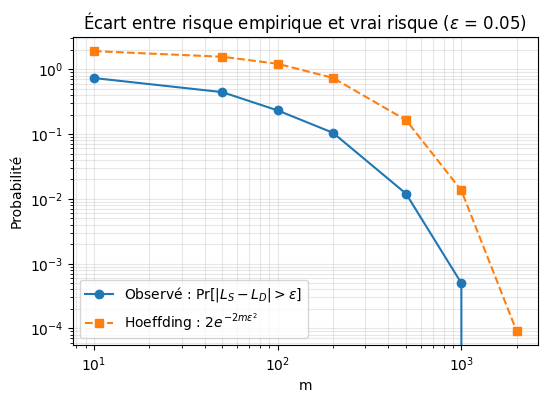

In [9]:
plt.figure(figsize=(6, 4))
plt.plot(m_values2, proba_obs, "o-", label=r"Observé : $\Pr[|L_S - L_D| > \epsilon]$")
plt.plot(m_values2, borne_hoeffding, "s--", label=r"Hoeffding : $2e^{-2m\epsilon^2}$")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("m")
plt.ylabel("Probabilité")
plt.title(r"Écart entre risque empirique et vrai risque ($\epsilon$ = %.2f)" % eps)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

**Remarque :** l'échelle verticale est logarithmique ; les points où la probabilité observée vaut exactement 0 (aucun écart $> \epsilon$ sur les 10 000 répétitions) ne peuvent donc pas être affichés.

### Discussion : la borne est-elle exacte ou conservative ?

- La probabilité observée est **toujours en dessous** de la borne de Hoeffding : la borne est bien respectée.
- La borne est **conservative** (pessimiste) : pour les petits $m$ elle est même supérieure à 1 (environ $1.9$ pour $m = 10$), ce qui ne donne aucune information. Pour les grands $m$, elle reste nettement au-dessus de la probabilité réelle (environ 10 fois plus grande, ou plus, à partir de $m = 500$).
- Pourquoi ? Hoeffding est valable pour **n'importe quelle** variable bornée dans $[0,1]$ et n'utilise pas la valeur de $p_j$. Elle correspond au pire cas, alors que la variance réelle $p_j(1-p_j) = 0.21$ est plus petite que le maximum $1/4$.
- En revanche, les deux courbes décroissent **exponentiellement** avec $m$ : la borne décrit bien la tendance, même si elle n'est pas exacte.

### Task 3 : From One Hypothesis to Uniform Convergence

On considère maintenant les $K = 5$ hypothèses de $\mathcal{H}$ en même temps. Pour chaque échantillon simulé, on génère les risques empiriques $L_S(h_1), \dots, L_S(h_K)$ et on calcule
$$\Delta_S = \max_{h \in \mathcal{H}} |L_S(h) - L_D(h)|.$$

On estime $\Pr[\Delta_S > \epsilon]$ et on la compare avec la borne de convergence uniforme pour une classe finie :
$$\Pr\left[\sup_{h \in \mathcal{H}} |L_S(h) - L_D(h)| > \epsilon\right] \le 2|\mathcal{H}|e^{-2m\epsilon^2}.$$

On garde $\epsilon = 0.05$ et les mêmes valeurs de $m$ qu'à la tâche 2.

*Remarque :* dans cette simulation simplifiée, les $E_j$ des différentes hypothèses sont tirés indépendamment.

In [10]:
K = len(p)

proba_unif = []
borne_unif = []

for m in m_values2:
    # Une ligne = un échantillon, une colonne = une hypothèse
    L = rng.binomial(m, p, size=(n_rep, K)) / m
    Delta = np.max(np.abs(L - p), axis=1)          # Delta_S pour chaque échantillon
    proba_unif.append(np.mean(Delta > eps))
    borne_unif.append(2 * K * np.exp(-2 * m * eps**2))

print("   m  | Pr[Delta_S > eps] observée | borne 2|H|exp(-2m eps^2)")
print("-" * 62)
for m, po, b in zip(m_values2, proba_unif, borne_unif):
    print("%5d |          %.4f            |        %.4f" % (m, po, b))

   m  | Pr[Delta_S > eps] observée | borne 2|H|exp(-2m eps^2)
--------------------------------------------------------------
   10 |          0.9950            |        9.5123
   50 |          0.8921            |        7.7880
  100 |          0.6683            |        6.0653
  200 |          0.3716            |        3.6788
  500 |          0.0647            |        0.8208
 1000 |          0.0029            |        0.0674
 2000 |          0.0000            |        0.0005


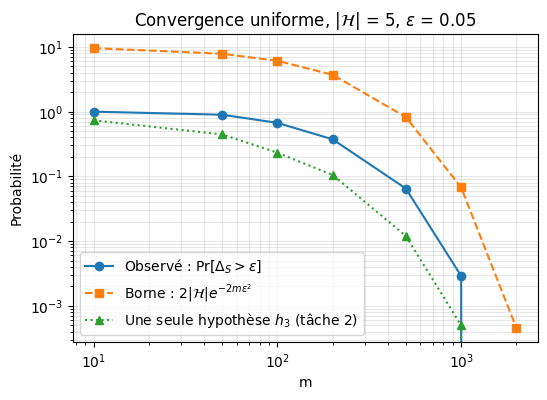

In [11]:
plt.figure(figsize=(6, 4))
plt.plot(m_values2, proba_unif, "o-", label=r"Observé : $\Pr[\Delta_S > \epsilon]$")
plt.plot(m_values2, borne_unif, "s--", label=r"Borne : $2|\mathcal{H}|e^{-2m\epsilon^2}$")
plt.plot(m_values2, proba_obs, "^:", label=r"Une seule hypothèse $h_3$ (tâche 2)")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("m")
plt.ylabel("Probabilité")
plt.title(r"Convergence uniforme, $|\mathcal{H}|$ = %d, $\epsilon$ = %.2f" % (K, eps))
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Discussion

- $\Pr[\Delta_S > \epsilon]$ est **plus grande** que la probabilité obtenue pour une seule hypothèse : il suffit qu'**une** des $K$ hypothèses ait un écart $> \epsilon$ pour que $\Delta_S > \epsilon$. Contrôler toutes les hypothèses en même temps est plus difficile que d'en contrôler une seule.
- La borne $2|\mathcal{H}|e^{-2m\epsilon^2}$ est toujours respectée, mais elle est encore plus conservative qu'à la tâche 2 : elle vient de la borne de l'union, qui additionne les probabilités des $K$ hypothèses comme si leurs « mauvais événements » ne se produisaient jamais en même temps, et elle applique Hoeffding (pire cas) à chacune.
- Quand $m$ augmente, $\Pr[\Delta_S > \epsilon]$ tend vers 0 : avec assez de données, **toutes** les hypothèses ont un risque empirique proche de leur vrai risque en même temps. C'est la convergence uniforme.

### Task 4 : Effect of the Size of the Hypothesis Class

On fixe $\epsilon = 0.05$ et on refait l'expérience de convergence uniforme pour $|\mathcal{H}| \in \{5, 10, 50, 100, 500\}$.

**Choix des vrais risques :** pour chaque taille de classe, les vrais risques $p_1, \dots, p_{|\mathcal{H}|}$ sont tirés uniformément dans $[0, 1]$ (une seule fois, puis gardés fixes).

In [12]:
H_sizes = [5, 10, 50, 100, 500]

# Vrais risques de chaque classe (tirés une fois, puis fixes)
p_H = {}
for taille in H_sizes:
    p_H[taille] = rng.uniform(0, 1, size=taille)

# proba_H[taille] = liste des Pr[Delta_S > eps] pour chaque m
proba_H = {}
for taille in H_sizes:
    proba_H[taille] = []
    for m in m_values2:
        L = rng.binomial(m, p_H[taille], size=(n_rep, taille)) / m
        Delta = np.max(np.abs(L - p_H[taille]), axis=1)
        proba_H[taille].append(np.mean(Delta > eps))

print("|H| \\ m " + "".join("%8d" % m for m in m_values2))
print("-" * 65)
for taille in H_sizes:
    print("%6d  " % taille + "".join("%8.4f" % v for v in proba_H[taille]))

|H| \ m       10      50     100     200     500    1000    2000
-----------------------------------------------------------------
     5    0.9838  0.7942  0.5586  0.2695  0.0350  0.0017  0.0000
    10    1.0000  0.9928  0.9320  0.6648  0.1250  0.0067  0.0000
    50    1.0000  1.0000  1.0000  0.9940  0.4443  0.0258  0.0003
   100    1.0000  1.0000  1.0000  0.9999  0.6148  0.0429  0.0001
   500    1.0000  1.0000  1.0000  1.0000  0.9932  0.2141  0.0008


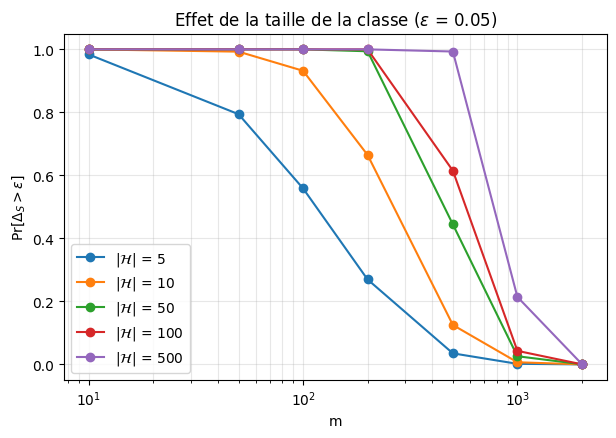

In [13]:
plt.figure(figsize=(7, 4.5))
for taille in H_sizes:
    plt.plot(m_values2, proba_H[taille], "o-", label=r"$|\mathcal{H}|$ = %d" % taille)
plt.xscale("log")
plt.xlabel("m")
plt.ylabel(r"$\Pr[\Delta_S > \epsilon]$")
plt.title(r"Effet de la taille de la classe ($\epsilon$ = %.2f)" % eps)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Discussion

- **Effet de $|\mathcal{H}|$ sur la convergence uniforme :** à $m$ fixé, plus la classe est grande, plus $\Pr[\Delta_S > \epsilon]$ est grande. Avec plus d'hypothèses, il y a plus de chances que l'une d'elles ait, par hasard, un risque empirique loin de son vrai risque. Les courbes se décalent vers la droite quand $|\mathcal{H}|$ augmente.
- **Une classe plus grande demande-t-elle plus de données ?** Oui : pour obtenir la même probabilité $\Pr[\Delta_S > \epsilon]$, il faut un $m$ plus grand quand $|\mathcal{H}|$ augmente.
- **Lien avec $\log|\mathcal{H}|$ :** le décalage est modéré. On multiplie $|\mathcal{H}|$ par 100 (de 5 à 500) mais le $m$ nécessaire est loin d'être multiplié par 100 (voir aussi la tâche 5). C'est cohérent avec les bornes de complexité d'échantillon des classes finies, $m \ge \log(2|\mathcal{H}|/\delta)/(2\epsilon^2)$ : la taille de la classe n'intervient qu'à travers $\log|\mathcal{H}|$, donc la quantité de données nécessaire croît lentement avec $|\mathcal{H}|$.

### Task 5 : Experimental Sample Complexity

On fixe $\epsilon = 0.05$ et $\delta = 0.05$ (on veut $\Delta_S \le 0.05$ avec probabilité au moins 95 %).

Pour chaque classe de la tâche 4, on teste $m = 50, 100, 150, \dots, 2500$ et on cherche le plus petit $m$ testé tel que $\Pr[\Delta_S > \epsilon] \le \delta$.

On compare avec la taille suffisante théorique :
$$m \ge \frac{\log(2|\mathcal{H}|/\delta)}{2\epsilon^2}.$$

In [14]:
delta = 0.05

# Valeurs de m testées (pas de 50)
m_test = np.arange(50, 2501, 50)

m_exp = []
m_th = []

for taille in H_sizes:
    # Plus petit m testé tel que Pr[Delta_S > eps] <= delta
    m_trouve = None
    for m in m_test:
        L = rng.binomial(m, p_H[taille], size=(n_rep, taille)) / m
        Delta = np.max(np.abs(L - p_H[taille]), axis=1)
        if np.mean(Delta > eps) <= delta:
            m_trouve = m
            break
    m_exp.append(m_trouve)
    # Taille suffisante donnée par la borne
    m_th.append(np.log(2 * taille / delta) / (2 * eps**2))

print(" |H| | m expérimental | m théorique")
print("-" * 38)
for taille, me, mt in zip(H_sizes, m_exp, m_th):
    print("%4d |     %5d      |   %6.0f" % (taille, me, np.ceil(mt)))

 |H| | m expérimental | m théorique
--------------------------------------
   5 |       500      |     1060
  10 |       700      |     1199
  50 |       900      |     1521
 100 |      1000      |     1659
 500 |      1300      |     1981


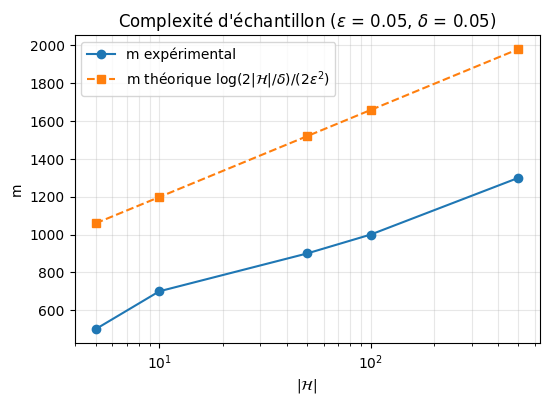

In [15]:
plt.figure(figsize=(6, 4))
plt.plot(H_sizes, m_exp, "o-", label="m expérimental")
plt.plot(H_sizes, m_th, "s--", label=r"m théorique $\log(2|\mathcal{H}|/\delta)/(2\epsilon^2)$")
plt.xscale("log")
plt.xlabel(r"$|\mathcal{H}|$")
plt.ylabel("m")
plt.title(r"Complexité d'échantillon ($\epsilon$ = %.2f, $\delta$ = %.2f)" % (eps, delta))
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Discussion

- Pour toutes les tailles de classe, le $m$ expérimental est **plus petit** que le $m$ théorique : en pratique, il faut moins de données que ce que la formule indique.
- Les deux augmentent avec $|\mathcal{H}|$, et de façon lente (logarithmique).
- **Pourquoi une garantie suffisante et pas le minimum exact ?** La formule vient de Hoeffding + borne de l'union. Ces deux étapes sont des majorations : Hoeffding traite le pire cas (variance $1/4$) sans tenir compte des vrais $p_j$, et la borne de l'union additionne les probabilités d'erreur de toutes les hypothèses. La formule garantit donc que $m$ est **assez grand** pour toute classe de taille $|\mathcal{H}|$ et toute distribution, mais pour une situation particulière, un $m$ plus petit peut déjà suffire.

## Part II – Simulating No-Free-Lunch

Domaine fini $\mathcal{X} = \{1, \dots, N\}$ avec la loi uniforme. À chaque répétition :
- on tire une nouvelle fonction cible $f$ avec $f(x) \sim \text{Bernoulli}(1/2)$ indépendamment pour chaque $x$ ;
- on tire un échantillon $S \sim D^m$ ($m$ points tirés uniformément, avec remise) ;
- le learner prédit le label observé si $x$ est dans l'échantillon, et $0$ sinon.

*Dans le code, les points sont numérotés de $0$ à $N-1$ (indices Python), ce qui ne change rien.*

**Choix des paramètres :**
- $N \in \{10, 50, 100\}$ : petit, moyen et grand domaine.
- $m \in \{5, 10, 20, 50, 100, 200, 500\}$ : de beaucoup moins de points que $N$ à beaucoup plus.
- 5 000 répétitions par couple $(N, m)$.

La fonction ci-dessous réalise une répétition. Le paramètre `regle` indique ce que le learner prédit sur les points non vus (il servira à la tâche 8).

In [16]:
def experience_nfl(N, m, regle="0"):
    # Une répétition : renvoie (fraction de points non vus, vrai risque du learner)
    f = rng.integers(0, 2, size=N)              # cible aléatoire, f(x) ~ Bernoulli(1/2)
    S = rng.integers(0, N, size=m)              # échantillon de m points uniformes

    vu = np.zeros(N, dtype=bool)
    vu[S] = True                                # vu[x] = True si x est dans l'échantillon
    fraction_non_vus = 1 - vu.mean()

    # Prédiction sur les points non vus
    if regle == "0":
        h = np.zeros(N, dtype=int)
    elif regle == "1":
        h = np.ones(N, dtype=int)
    else:                                       # "aleatoire" : label Bernoulli(1/2)
        h = rng.integers(0, 2, size=N)

    h[vu] = f[vu]                               # sur les points vus : label observé
    risque = np.mean(h != f)                    # L_D(A(S)) sur tout le domaine
    return fraction_non_vus, risque


N_values = [10, 50, 100]
m_nfl = [5, 10, 20, 50, 100, 200, 500]
n_rep_nfl = 5000

### Task 6 : Seen and Unseen Inputs

Pour chaque $(N, m)$ on répète l'expérience et on estime l'espérance de la fraction de points non vus. On la compare avec
$$\Pr[x \text{ non vu}] = \left(1 - \frac{1}{N}\right)^m.$$

On garde aussi le risque de chaque répétition pour la tâche 7.

In [17]:
frac_moy = {}     # frac_moy[N] = fraction moyenne de non vus pour chaque m
risque_moy = {}   # risque_moy[N] = risque moyen du learner (servira à la tâche 7)

for N in N_values:
    frac_moy[N] = []
    risque_moy[N] = []
    for m in m_nfl:
        resultats = np.array([experience_nfl(N, m) for _ in range(n_rep_nfl)])
        frac_moy[N].append(resultats[:, 0].mean())
        risque_moy[N].append(resultats[:, 1].mean())

print("   N |   m  | fraction non vus simulée | (1 - 1/N)^m")
print("-" * 56)
for N in N_values:
    for m, fr in zip(m_nfl, frac_moy[N]):
        print("%4d | %4d |         %.4f           |   %.4f" % (N, m, fr, (1 - 1 / N)**m))

   N |   m  | fraction non vus simulée | (1 - 1/N)^m
--------------------------------------------------------
  10 |    5 |         0.5900           |   0.5905
  10 |   10 |         0.3506           |   0.3487
  10 |   20 |         0.1219           |   0.1216
  10 |   50 |         0.0052           |   0.0052
  10 |  100 |         0.0000           |   0.0000
  10 |  200 |         0.0000           |   0.0000
  10 |  500 |         0.0000           |   0.0000
  50 |    5 |         0.9040           |   0.9039
  50 |   10 |         0.8171           |   0.8171
  50 |   20 |         0.6676           |   0.6676
  50 |   50 |         0.3651           |   0.3642
  50 |  100 |         0.1334           |   0.1326
  50 |  200 |         0.0177           |   0.0176
  50 |  500 |         0.0000           |   0.0000
 100 |    5 |         0.9510           |   0.9510
 100 |   10 |         0.9043           |   0.9044
 100 |   20 |         0.8177           |   0.8179
 100 |   50 |         0.6051           |

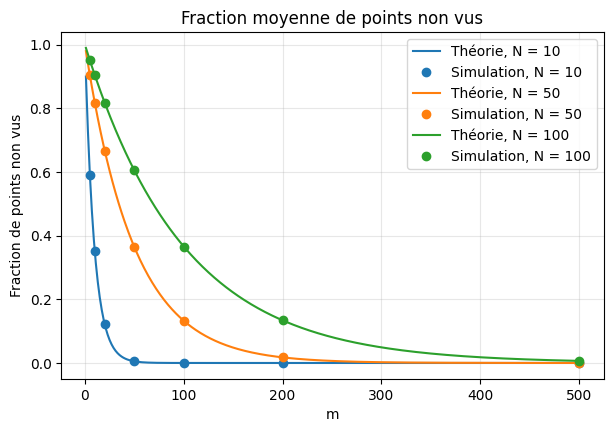

In [18]:
m_continu = np.arange(1, 501)

plt.figure(figsize=(7, 4.5))
for N in N_values:
    courbe = plt.plot(m_continu, (1 - 1 / N)**m_continu, "-", label="Théorie, N = %d" % N)
    plt.plot(m_nfl, frac_moy[N], "o", color=courbe[0].get_color(), label="Simulation, N = %d" % N)
plt.xlabel("m")
plt.ylabel("Fraction de points non vus")
plt.title("Fraction moyenne de points non vus")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Discussion

- Les valeurs simulées sont très proches de $(1 - 1/N)^m$ pour tous les $(N, m)$.
- **Pourquoi $(1-1/N)^m$ ?** Un tirage donne un point différent de $x$ avec probabilité $1 - 1/N$. Les $m$ tirages sont indépendants, donc $x$ n'est jamais tiré avec probabilité $(1 - 1/N)^m$.
- **Pourquoi c'est aussi la fraction moyenne de non vus ?** La fraction de non vus s'écrit $\frac{1}{N}\sum_{x \in \mathcal{X}} \mathbf{1}[x \text{ non vu}]$. Par linéarité de l'espérance :
$$\mathbb{E}\left[\frac{1}{N}\sum_{x} \mathbf{1}[x \text{ non vu}]\right] = \frac{1}{N}\sum_{x} \Pr[x \text{ non vu}] = \frac{1}{N} \cdot N \left(1-\frac{1}{N}\right)^m = \left(1-\frac{1}{N}\right)^m,$$
car tous les points ont la même probabilité d'être non vus (loi uniforme).
- Plus $N$ est grand, plus il faut de données pour voir tout le domaine : avec $m = N$, il reste encore environ $e^{-1} \approx 37\%$ de points non vus.

### Task 7 : Error on Unseen Inputs

Vrai risque du learner par mémorisation sur tout le domaine :
$$L_D(A(S)) = \frac{1}{N}\sum_{x \in \mathcal{X}} \mathbf{1}[A(S)(x) \ne f(x)].$$

**Dérivation théorique :**
- Si $x$ est vu, le learner prédit son vrai label : erreur $= 0$.
- Si $x$ n'est pas vu, le learner prédit $0$ ; il se trompe si $f(x) = 1$. Comme $f(x) \sim \text{Bernoulli}(1/2)$ est indépendant de l'échantillon, cette erreur a une probabilité $1/2$.

Donc pour chaque $x$ : $\Pr[A(S)(x) \ne f(x)] = \Pr[x \text{ non vu}] \cdot \frac{1}{2}$, et par linéarité de l'espérance :
$$\mathbb{E}[L_D(A(S))] = \frac{1}{N}\sum_{x} \frac{1}{2}\left(1-\frac{1}{N}\right)^m = \frac{1}{2}\left(1 - \frac{1}{N}\right)^m.$$

Les risques ont déjà été simulés à la tâche 6 (mêmes cibles et mêmes échantillons).

In [19]:
print("   N |   m  | risque simulé | 1/2 (1 - 1/N)^m")
print("-" * 48)
for N in N_values:
    for m, r in zip(m_nfl, risque_moy[N]):
        print("%4d | %4d |    %.4f     |     %.4f" % (N, m, r, 0.5 * (1 - 1 / N)**m))

   N |   m  | risque simulé | 1/2 (1 - 1/N)^m
------------------------------------------------
  10 |    5 |    0.2943     |     0.2952
  10 |   10 |    0.1745     |     0.1743
  10 |   20 |    0.0615     |     0.0608
  10 |   50 |    0.0027     |     0.0026
  10 |  100 |    0.0000     |     0.0000
  10 |  200 |    0.0000     |     0.0000
  10 |  500 |    0.0000     |     0.0000
  50 |    5 |    0.4502     |     0.4520
  50 |   10 |    0.4079     |     0.4085
  50 |   20 |    0.3322     |     0.3338
  50 |   50 |    0.1818     |     0.1821
  50 |  100 |    0.0670     |     0.0663
  50 |  200 |    0.0088     |     0.0088
  50 |  500 |    0.0000     |     0.0000
 100 |    5 |    0.4761     |     0.4755
 100 |   10 |    0.4521     |     0.4522
 100 |   20 |    0.4093     |     0.4090
 100 |   50 |    0.3022     |     0.3025
 100 |  100 |    0.1830     |     0.1830
 100 |  200 |    0.0671     |     0.0670
 100 |  500 |    0.0032     |     0.0033


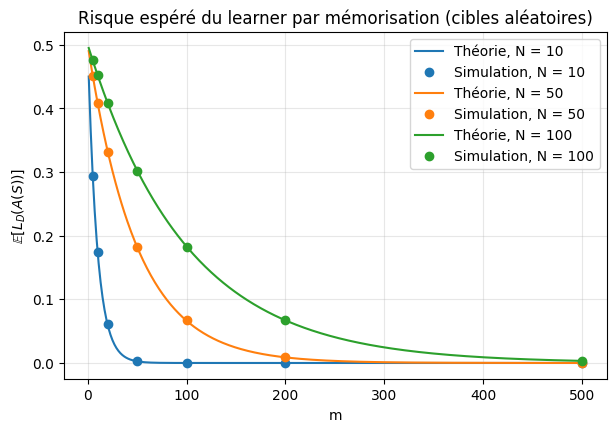

In [20]:
plt.figure(figsize=(7, 4.5))
for N in N_values:
    courbe = plt.plot(m_continu, 0.5 * (1 - 1 / N)**m_continu, "-", label="Théorie, N = %d" % N)
    plt.plot(m_nfl, risque_moy[N], "o", color=courbe[0].get_color(), label="Simulation, N = %d" % N)
plt.xlabel("m")
plt.ylabel(r"$\mathbb{E}[L_D(A(S))]$")
plt.title("Risque espéré du learner par mémorisation (cibles aléatoires)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Discussion

- La simulation suit très bien la formule $\frac{1}{2}(1 - 1/N)^m$.
- Le risque vaut exactement « la moitié de la fraction de points non vus » : le learner ne fait **aucune erreur** sur les points vus et se trompe **une fois sur deux** sur les points non vus, c'est-à-dire qu'il ne fait pas mieux que le hasard dès qu'il sort de l'échantillon.
- Le risque ne diminue que parce que l'échantillon finit par couvrir le domaine. Tant que $m$ est petit devant $N$, le risque reste proche de $1/2$.

### Task 8 : Changing the Prediction on Unseen Inputs

On compare trois règles pour les points non vus : toujours prédire $0$, toujours prédire $1$, prédire un label aléatoire $\text{Bernoulli}(1/2)$. On prend $N = 50$.

In [21]:
N = 50
regles = ["0", "1", "aleatoire"]
noms = {"0": "toujours 0", "1": "toujours 1", "aleatoire": "aléatoire Bernoulli(1/2)"}

risque_regle = {}
for regle in regles:
    risque_regle[regle] = []
    for m in m_nfl:
        risques = [experience_nfl(N, m, regle)[1] for _ in range(n_rep_nfl)]
        risque_regle[regle].append(np.mean(risques))

print("   m  | toujours 0 | toujours 1 | aléatoire | théorie 1/2 (1-1/N)^m")
print("-" * 68)
for i, m in enumerate(m_nfl):
    print("%5d |   %.4f   |   %.4f   |  %.4f   |   %.4f"
          % (m, risque_regle["0"][i], risque_regle["1"][i], risque_regle["aleatoire"][i],
             0.5 * (1 - 1 / N)**m))

   m  | toujours 0 | toujours 1 | aléatoire | théorie 1/2 (1-1/N)^m
--------------------------------------------------------------------
    5 |   0.4533   |   0.4516   |  0.4533   |   0.4520
   10 |   0.4067   |   0.4076   |  0.4081   |   0.4085
   20 |   0.3343   |   0.3345   |  0.3327   |   0.3338
   50 |   0.1816   |   0.1817   |  0.1826   |   0.1821
  100 |   0.0655   |   0.0659   |  0.0658   |   0.0663
  200 |   0.0083   |   0.0088   |  0.0088   |   0.0088
  500 |   0.0000   |   0.0000   |  0.0000   |   0.0000


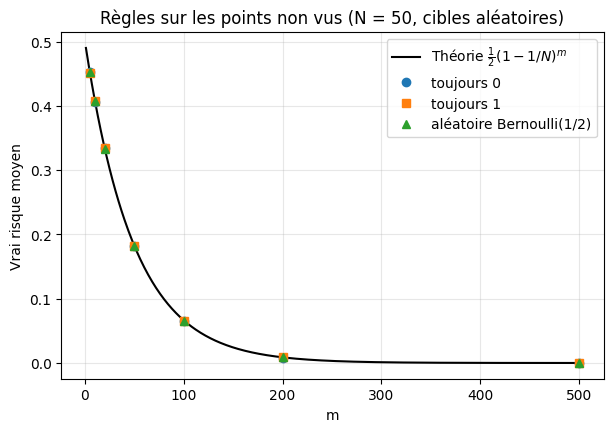

In [22]:
plt.figure(figsize=(7, 4.5))
plt.plot(m_continu, 0.5 * (1 - 1 / N)**m_continu, "k-", label=r"Théorie $\frac{1}{2}(1-1/N)^m$")
for regle, marqueur in zip(regles, ["o", "s", "^"]):
    plt.plot(m_nfl, risque_regle[regle], marqueur, label=noms[regle])
plt.xlabel("m")
plt.ylabel("Vrai risque moyen")
plt.title("Règles sur les points non vus (N = %d, cibles aléatoires)" % N)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Discussion

- Les trois règles donnent **le même risque moyen**, égal à $\frac{1}{2}(1 - 1/N)^m$ ; les petites différences viennent uniquement du bruit Monte-Carlo. **Aucune stratégie ne fait systématiquement mieux que les autres.**
- Explication : sur un point non vu, $f(x)$ vaut $0$ ou $1$ avec probabilité $1/2$, indépendamment de l'échantillon. Quelle que soit la prédiction (0, 1 ou un tirage au hasard), elle est juste avec probabilité $1/2$.
- **Lien avec le No-Free-Lunch :** quand toutes les fonctions cibles sont possibles et également probables, l'échantillon ne donne **aucune information** sur les labels des points non vus. En moyenne sur toutes les cibles, aucun algorithme ne peut faire mieux qu'un autre sur ces points : pour toute règle, il y a autant de cibles où elle a raison que de cibles où elle a tort. Pour faire mieux que le hasard hors de l'échantillon, il faut faire une hypothèse sur la cible.

## Part III – Introducing Prior Knowledge

Même domaine $\mathcal{X} = \{1, \dots, N\}$ (loi uniforme), mais la cible est maintenant un seuil
$$f_\theta(x) = \mathbf{1}[x > \theta], \qquad \theta \in \{1, \dots, N-1\}.$$

Le learner utilise la classe des seuils $\mathcal{H} = \{h_t(x) = \mathbf{1}[x > t] : t \in \{1, \dots, N-1\}\}$ et choisit le seuil par ERM (seuil qui minimise l'erreur sur l'échantillon ; en cas d'égalité, on prend le premier).

### Task 9 : Learning with a Matching Inductive Bias

On prend $N = 50$ et les mêmes $m$ que dans la partie II, pour pouvoir comparer. À chaque répétition, $\theta$ est tiré uniformément dans $\{1, \dots, N-1\}$.

In [23]:
N = 50
X = np.arange(1, N + 1)          # domaine {1, ..., N}
seuils = np.arange(1, N)         # seuils possibles t = 1, ..., N-1

def experience_seuil(N, m):
    # Une répétition : renvoie le vrai risque L_D(h_S) de l'ERM
    theta = rng.integers(1, N)                       # (a) cible seuil f_theta
    x = rng.integers(1, N + 1, size=m)               # (b) échantillon
    y = (x > theta).astype(int)

    # (c) ERM : erreur empirique de chaque seuil t, puis choix du minimum
    predictions = (x[None, :] > seuils[:, None]).astype(int)   # une ligne par seuil
    erreurs = np.mean(predictions != y[None, :], axis=1)
    t_S = seuils[np.argmin(erreurs)]

    # (d) vrai risque sur tout le domaine
    return np.mean((X > t_S) != (X > theta))


risque_seuil = []
for m in m_nfl:
    risques = [experience_seuil(N, m) for _ in range(n_rep_nfl)]
    risque_seuil.append(np.mean(risques))

print("   m  | E[L_D(h_S)] seuils | E[L_D] cibles aléatoires (partie II)")
print("-" * 62)
for m, rs, ra in zip(m_nfl, risque_seuil, risque_moy[N]):
    print("%5d |       %.4f       |         %.4f" % (m, rs, ra))

   m  | E[L_D(h_S)] seuils | E[L_D] cibles aléatoires (partie II)
--------------------------------------------------------------
    5 |       0.1329       |         0.4502
   10 |       0.0713       |         0.4079
   20 |       0.0362       |         0.3322
   50 |       0.0107       |         0.1818
  100 |       0.0031       |         0.0670
  200 |       0.0003       |         0.0088
  500 |       0.0000       |         0.0000


### Discussion

- Avec des cibles seuils et l'ERM sur les seuils, le risque est **beaucoup plus faible** qu'avec des cibles aléatoires pour le même $m$. Par exemple, avec seulement $m = 20$ points (donc environ 67 % du domaine jamais vu), le risque est d'environ $0.04$, alors qu'il est d'environ $0.33$ pour les cibles aléatoires.
- L'ERM atteint toujours une erreur empirique nulle, puisque la vraie cible appartient à la classe $\mathcal{H}$.

### Task 10 : Random Targets vs. Structured Targets

On trace l'évolution du vrai risque avec $m$ ($N = 50$) pour :
- (a) des cibles complètement aléatoires (learner par mémorisation de la partie II) ;
- (b) des cibles seuils apprises par ERM sur la classe des seuils.

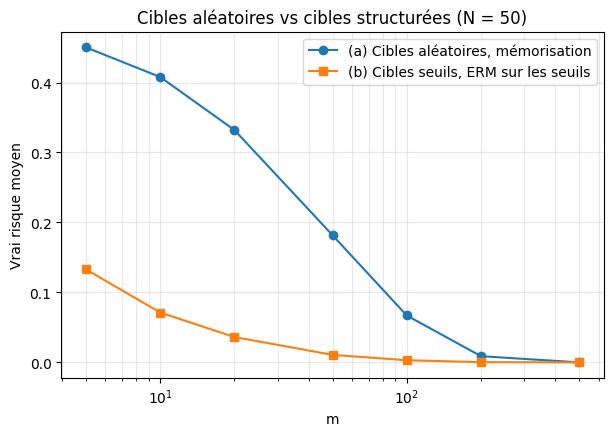

In [24]:
plt.figure(figsize=(7, 4.5))
plt.plot(m_nfl, risque_moy[N], "o-", label="(a) Cibles aléatoires, mémorisation")
plt.plot(m_nfl, risque_seuil, "s-", label="(b) Cibles seuils, ERM sur les seuils")
plt.xscale("log")
plt.xlabel("m")
plt.ylabel("Vrai risque moyen")
plt.title("Cibles aléatoires vs cibles structurées (N = %d)" % N)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Discussion

- **Pourquoi le learner généralise beaucoup mieux dans le cas (b) ?** Une cible seuil est entièrement déterminée par un seul nombre $\theta$. Les points de l'échantillon permettent d'encadrer $\theta$ : si on a vu un point $a$ de label $0$ et un point $b$ de label $1$, alors $a \le \theta < b$. Tous les points non vus à gauche de $a$ ont forcément le label $0$ et tous ceux à droite de $b$ le label $1$. Le learner peut donc prédire correctement des points qu'il n'a **jamais vus** ; seuls les points entre $a$ et $b$ restent incertains, et cet intervalle se réduit vite quand $m$ augmente.
- Dans le cas (a), connaître $f$ sur certains points ne dit rien sur les autres : chaque point non vu est une erreur avec probabilité $1/2$.
- **Rôle de l'hypothèse « la cible est un seuil » :** c'est cette hypothèse qui relie les labels des différents points entre eux. Sans elle, il y a $2^N$ cibles possibles et l'échantillon ne réduit l'incertitude que sur les points vus. Avec elle, il ne reste que $N-1$ cibles possibles, et chaque exemple élimine beaucoup de seuils d'un coup. Cette hypothèse est correcte ici (la vraie cible est bien un seuil), c'est pour cela qu'elle aide.

### Task 11 : Final Analysis

- **Concentration de $L_S(h)$ autour de $L_D(h)$ :** $L_S(h)$ est une moyenne de $m$ erreurs indépendantes. Son espérance est $L_D(h)$ et son écart-type $\sqrt{p(1-p)/m}$ diminue en $1/\sqrt{m}$ (tâche 1). La probabilité d'un écart $> \epsilon$ décroît exponentiellement avec $m$, comme le prévoit Hoeffding (tâche 2).
- **Pourquoi la convergence uniforme demande un contrôle simultané :** l'ERM choisit l'hypothèse de plus petit risque empirique. Pour que ce choix soit fiable, il faut que le risque empirique soit proche du vrai risque pour **toutes** les hypothèses en même temps, sinon l'ERM risque de choisir une hypothèse qui a « eu de la chance » sur l'échantillon. C'est ce que mesure $\Delta_S$, et $\Pr[\Delta_S > \epsilon]$ est plus grande que pour une seule hypothèse (tâche 3).
- **Effet de $|\mathcal{H}|$ :** plus il y a d'hypothèses, plus il est probable que l'une d'elles s'écarte de son vrai risque, donc il faut plus de données pour garder le même contrôle simultané. Mais l'augmentation est lente, en $\log|\mathcal{H}|$ (tâches 4 et 5).
- **Pourquoi les bornes théoriques sont conservatives :** elles reposent sur Hoeffding (pire cas, sans utiliser les vrais $p_j$) et sur la borne de l'union (qui additionne les probabilités). Elles sont valables pour toute distribution, donc pour un cas particulier elles surestiment la probabilité d'erreur et la taille d'échantillon nécessaire (tâches 2, 3 et 5).
- **Cibles aléatoires et labels non vus :** quand $f(x) \sim \text{Bernoulli}(1/2)$ indépendamment pour chaque $x$, le label d'un point non vu est indépendant de l'échantillon. Aucune prédiction ne peut faire mieux que $1/2$ d'erreur sur ces points (tâches 6 et 7).
- **No-Free-Lunch :** toutes les règles testées sur les points non vus ont le même risque moyen (tâche 8). Le seul moyen de réduire le risque est de voir plus de points : un learner ne peut pas deviner des labels arbitraires à partir de l'échantillon seul.
- **Les seuils comme connaissance a priori :** supposer que la cible est un seuil, et chercher la solution dans la classe des seuils, revient à donner au learner une information sur la structure de la cible avant de voir les données. On passe de $2^N$ cibles possibles à $N-1$.
- **Pourquoi ce biais inductif permet de généraliser :** grâce à la structure de seuil, les exemples observés déterminent aussi les labels de nombreux points non vus. Le risque devient faible bien avant que l'échantillon couvre tout le domaine (tâches 9 et 10). Généraliser au-delà des exemples observés n'est donc possible qu'en combinant des données **et** une hypothèse sur la cible (un biais inductif) adaptée au problème.